# Cox-Ross-Rubinstein Binomial Option Pricing

The binomial option pricing model represents the evolution of a stock price over discrete time steps, where at each step the stock can move either **up** or **down** by a specified factor.

Starting from the current stock price, the tree is constructed forward until the option's expiry, where the payoff is calculated at each terminal node. The option is then valued by working backwards through the tree using **risk-neutral probabilities** and discounting, ultimately obtaining the option's value today. This process is known as **backward induction**.


In [109]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))

from src.black_scholes import black_scholes_price
from src.binomial import crr_price

Model Parameters

In [110]:
S0 = 100       # Initial stock price
K = 100        # Strike price
T = 1.0        # Time to maturity (years)
r = 0.05       # Risk-free rate
sigma = 0.20   # Volatility
N = 500         # Number of time steps

In [111]:
dt = T/N

In [112]:
u = np.exp(sigma * np.sqrt(dt))

In [113]:
d = 1/u

In [114]:
p = (np.exp(r*dt) - d) / (u - d)

In [115]:
print(dt)
print(u)
print(d)
print(p)

0.002
1.0089843914341023
0.9910956090992324
0.5033543218524357


In [116]:
stock_tree = np.zeros((N + 1, N + 1))

In [117]:
for i in range(N + 1):
    for j in range(i + 1):
        stock_price = S0 * (u ** j) * (d ** (i - j))
        stock_tree[j, i] = stock_price

In [118]:
stock_tree

array([[1.00000000e+02, 9.91095609e+01, 9.82270506e+01, ...,
        1.16290685e+00, 1.15255187e+00, 1.14228910e+00],
       [0.00000000e+00, 1.00898439e+02, 1.00000000e+02, ...,
        1.18389674e+00, 1.17335486e+00, 1.16290685e+00],
       [0.00000000e+00, 0.00000000e+00, 1.01804950e+02, ...,
        1.20526549e+00, 1.19453333e+00, 1.18389674e+00],
       ...,
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        8.59914103e+03, 8.52257092e+03, 8.44668262e+03],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 8.67639908e+03, 8.59914103e+03],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 8.75435125e+03]], shape=(501, 501))

In [119]:
option_tree = np.zeros((N + 1, N + 1))

In [120]:
for i in range(N + 1):
    for j in range(i + 1):
        option_tree[j, N] = max(stock_tree[j, N] - K, 0)
        




In [121]:
option_tree

array([[   0.        ,    0.        ,    0.        , ...,    0.        ,
           0.        ,    0.        ],
       [   0.        ,    0.        ,    0.        , ...,    0.        ,
           0.        ,    0.        ],
       [   0.        ,    0.        ,    0.        , ...,    0.        ,
           0.        ,    0.        ],
       ...,
       [   0.        ,    0.        ,    0.        , ...,    0.        ,
           0.        , 8346.68261518],
       [   0.        ,    0.        ,    0.        , ...,    0.        ,
           0.        , 8499.14103126],
       [   0.        ,    0.        ,    0.        , ...,    0.        ,
           0.        , 8654.35124586]], shape=(501, 501))

In [122]:
for i in range(N - 1, -1, -1):
    for j in range(i + 1):
        C_down = option_tree[j, i + 1]
        C_up = option_tree[j + 1, i + 1]

        option_tree[j, i] = np.exp(-r * dt) * (p * C_up + (1 - p) * C_down)

In [123]:
print(f"CRR European call price: {option_tree[0, 0]:.6f}")

CRR European call price: 10.446585


## Reusable CRR Option Pricer

The manual implementation above is validated using the reusable CRR pricing function in `src.binomial`, which supports both European and American call and put options.

In [124]:
crr_price(
    100, 100, 1.0, 0.05, 0.20,
    N=500,
    option_type="call",
    american=False,
)

np.float64(10.44658513644654)

In [125]:
N_values = [5, 10, 25, 50, 100, 250, 500]

In [126]:
crr_prices = []

for N in N_values:
    price = crr_price(
        S0, K, T, r, sigma,
        N=N,
        option_type="call",
        american=False,
    )
    crr_prices.append(price)

In [127]:
crr_prices

[np.float64(10.805933920410084),
 np.float64(10.25340904487193),
 np.float64(10.520965623983946),
 np.float64(10.410691540732644),
 np.float64(10.430611662249113),
 np.float64(10.442588712621925),
 np.float64(10.44658513644654)]

In [128]:
bs_price = black_scholes_price(
    S0, K, T, r, 0.0, sigma, "call"
)

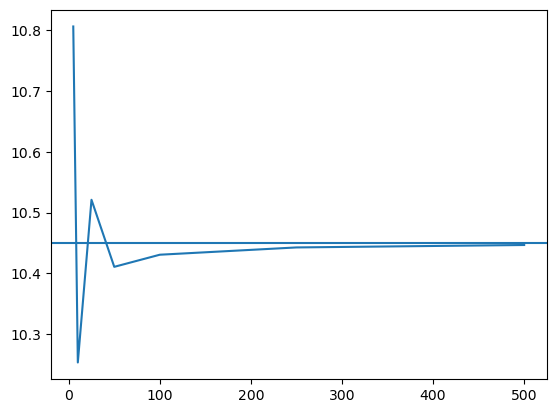

In [129]:
plt.plot(N_values, crr_prices)

plt.axhline(y=bs_price)

### Convergence Results

The CRR estimate oscillates around the Black-Scholes benchmark for smaller numbers of time steps, reflecting the discrete structure of the binomial tree. As the number of steps increases, the magnitude of the pricing error decreases and the CRR estimate converges towards the Black-Scholes price. At $N=500$, the CRR call price is approximately $10.4466$, compared with a Black-Scholes price of approximately $10.4506$, demonstrating close numerical agreement between the two pricing methods.

## American Options

Unlike European options, American options may be exercised at any time before expiry. At each node, the option value is therefore the maximum of the immediate exercise value and the discounted continuation value.

In [130]:
european_call = crr_price(
    S0, K, T, r, sigma, 500, "call", american=False
)

american_call = crr_price(
    S0, K, T, r, sigma, 500, "call", american=True
)

european_put = crr_price(
    S0, K, T, r, sigma, 500, "put", american=False
)

american_put = crr_price(
    S0, K, T, r, sigma, 500, "put", american=True
)

print("European Call:", european_call)
print("American Call:", american_call)
print("European Put:", european_put)
print("American Put:", american_put)

European Call: 10.44658513644654
American Call: 10.44658513644654
European Put: 5.5695275865157745
American Put: 6.088810110703037
